# 08 Advanced time-series feature engineering

NASA C-MAPSS FD001 training telemetry. Each feature uses the current reading and available prior readings from the same engine, ordered by operating cycle. RUL is retained as the target for later experiments.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.feature_engineering import INFORMATIVE_SENSORS, generate_enhanced_training_dataset
from src.preprocessing import CANONICAL_15_FEATURES

sns.set_theme(style="whitegrid")
fig_dir = project_root / "reports" / "figures" / "feature_engineering"
fig_dir.mkdir(parents=True, exist_ok=True)

def show_figure(fig, filename):
    fig.savefig(fig_dir / filename, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## Original and enhanced feature sets

The original inputs are cycle number and 14 sensor readings. Each sensor contributes two trailing means, two trailing sample standard deviations, one first difference, and one trailing least-squares slope. Cross-sensor summaries were omitted because the sensors measure different quantities on different scales.

Windows start with the observations available at each cycle. A one-reading window has zero standard deviation and slope, and each engine starts with a zero first difference.

In [2]:
enhanced, feature_cols, dictionary = generate_enhanced_training_dataset()
baseline = enhanced[CANONICAL_15_FEATURES]
display(baseline.head())
display(pd.DataFrame(
    {"Training rows": [len(baseline), len(enhanced)],
     "Input features": [baseline.shape[1], len(feature_cols)]},
    index=["Original", "Enhanced"],
))

,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,2,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,3,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,4,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,5,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


,Training rows,Input features
Original,20631,15
Enhanced,20631,99


## Feature dictionary

The full dictionary accompanies the enhanced training CSV in `data/processed/`. These are the definitions for sensor 11.

In [3]:
sensor = "sensor_11"
display(pd.Series({
    name: description for name, description in dictionary.items()
    if name == sensor or name.startswith(f"{sensor}_")
}, name="Definition").to_frame())

,Definition
sensor_11,Current reading of HPC outlet static pressure (psia).
sensor_11_roll_mean_5,"Mean of HPC outlet static pressure (psia) over the last 5 observations of the same engine, including the current reading. Uses available history at startup."
sensor_11_roll_std_5,"Sample standard deviation (ddof=1) of HPC outlet static pressure (psia) over the last 5 observations of the same engine, including the current reading. Uses available history and is zero with one observation."
sensor_11_roll_mean_10,"Mean of HPC outlet static pressure (psia) over the last 10 observations of the same engine, including the current reading. Uses available history at startup."
sensor_11_roll_std_10,"Sample standard deviation (ddof=1) of HPC outlet static pressure (psia) over the last 10 observations of the same engine, including the current reading. Uses available history and is zero with one observation."
sensor_11_diff_1,Current minus previous observation of HPC outlet static pressure (psia) for the same engine. Zero on the first observation.
sensor_11_slope_5,"Least-squares slope of HPC outlet static pressure (psia) against time_cycles over the last 5 observations of the same engine, including the current reading. Reported in sensor units per cycle. Uses available history and is zero with one observation."


## Trailing means for engine 1

Window 5 reacts more quickly to a change in sensor 11. Window 10 averages a longer stretch of readings.

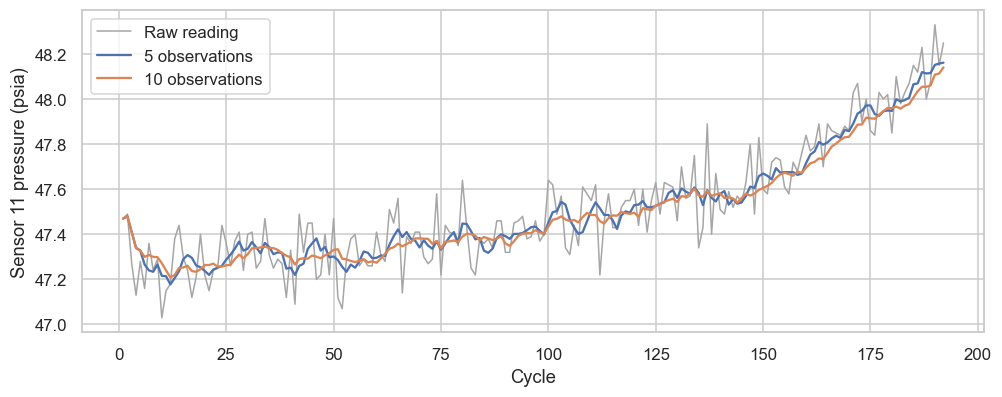

In [4]:
engine = enhanced.loc[enhanced["unit_number"].eq(1)]
cycles = engine["time_cycles"]
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.plot(cycles, engine[sensor], color="0.65", linewidth=1, label="Raw reading")
ax.plot(cycles, engine[f"{sensor}_roll_mean_5"], label="5 observations")
ax.plot(cycles, engine[f"{sensor}_roll_mean_10"], label="10 observations")
ax.set(xlabel="Cycle", ylabel="Sensor 11 pressure (psia)")
ax.legend()
show_figure(fig, "rolling_mean_example.png")

## Trailing standard deviations for engine 1

Both windows use the sample standard deviation of the readings available at each cycle.

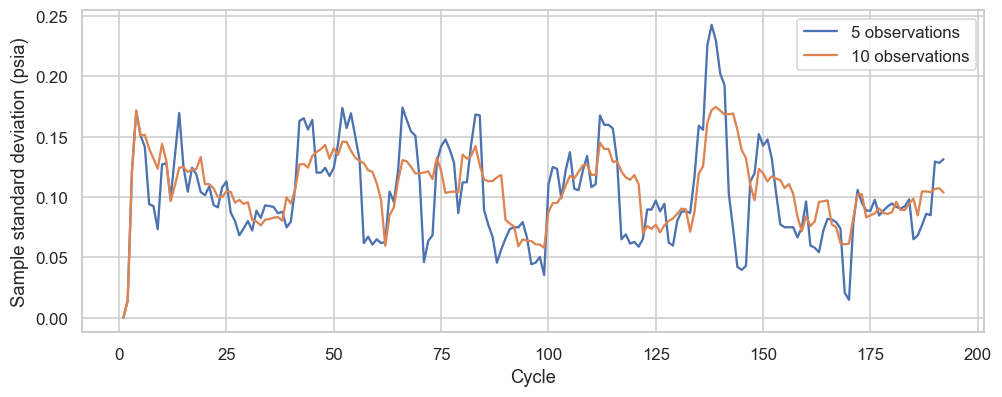

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.plot(cycles, engine[f"{sensor}_roll_std_5"], label="5 observations")
ax.plot(cycles, engine[f"{sensor}_roll_std_10"], label="10 observations")
ax.set(xlabel="Cycle", ylabel="Sample standard deviation (psia)")
ax.legend()
show_figure(fig, "rolling_std_example.png")

## Recent sensor trend for engine 1

At each cycle, fit a line to the last five available sensor readings against their cycle numbers. A positive slope indicates rising pressure over that trailing window.

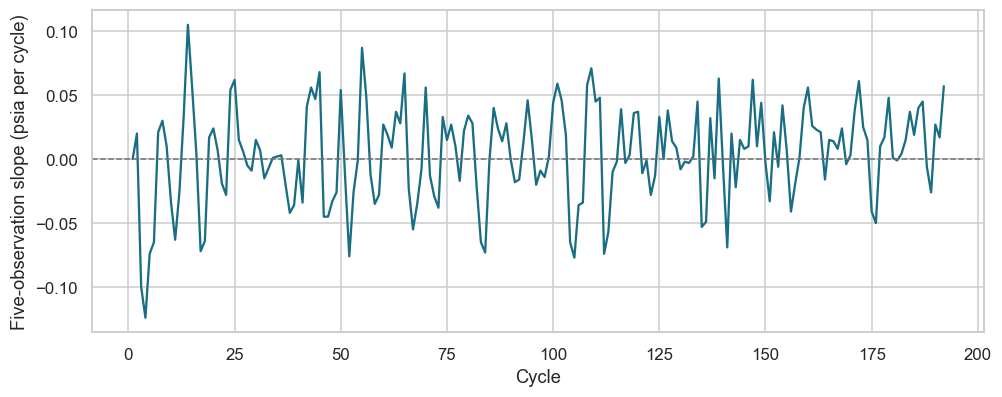

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.plot(cycles, engine[f"{sensor}_slope_5"], color="#196e83")
ax.axhline(0, color="0.45", linestyle="--", linewidth=1)
ax.set(xlabel="Cycle", ylabel="Five-observation slope (psia per cycle)")
show_figure(fig, "sensor_trend_example.png")

## Correlations among model inputs

The Pearson heatmap includes all 99 input features across the training observations. Each seven-column sensor block contains the raw reading, both rolling means and standard deviations, the difference, and the slope.

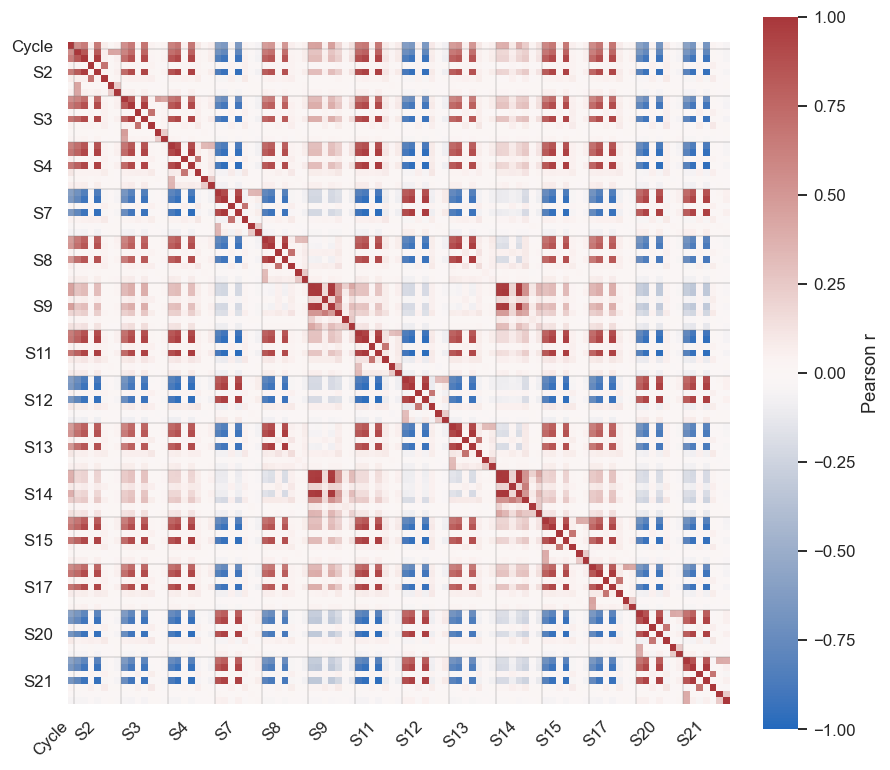

In [7]:
ordered_cols = ["time_cycles"]
sensor_blocks = []
for name in INFORMATIVE_SENSORS:
    block = [col for col in feature_cols if col == name or col.startswith(f"{name}_")]
    sensor_blocks.append(len(block))
    ordered_cols.extend(block)

correlations = enhanced[ordered_cols].corr()
edges = np.cumsum([1, *sensor_blocks])
centers = (np.r_[0, edges[:-1]] + edges) / 2
labels = ["Cycle", *[name.replace("sensor_", "S") for name in INFORMATIVE_SENSORS]]

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
sns.heatmap(correlations, cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson r"}, ax=ax)
for edge in edges[:-1]:
    ax.axhline(edge, color="0.5", linewidth=0.25)
    ax.axvline(edge, color="0.5", linewidth=0.25)
ax.set_xticks(centers, labels, rotation=45, ha="right")
ax.set_yticks(centers, labels, rotation=0)
show_figure(fig, "engineered_features_correlation.png")